# Model experiments

Central workspace for comparing architectures under a shared protocol. Architecture definitions live in `src/models/`; preparation, training, and evaluation are shared in `src/experiments.py`. Start by comparing saved models. Training is explicitly disabled by default. Character-level diagnostics belong to notebook 05.

The existing artifacts are historical single-seed experiments. Their split and class mapping are documented in the earlier notebooks, but not all have machine-readable provenance. New runs record both. The test set remains reserved for final evaluation.

In [9]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models import MODELS
from src.experiments import DEFAULT_TRAINING, prepare_data, train_model, compare_models

## 1. Common data and training settings

In [10]:
training_settings = DEFAULT_TRAINING.copy()
frames, unique_char = prepare_data(seed=training_settings["seed"])
df_train = frames["train"]
df_valid = frames["validation"]
df_test = frames["test"]
BATCH_SIZE = training_settings["batch_size"]
SEED = training_settings["seed"]

display(pd.DataFrame([
    {"Split": name, "Images": len(df), "Writers": df.writer_id.nunique()}
    for name, df in frames.items()
]).set_index("Split"))

,Images,Writers
Split,,
train,47375,987
validation,10128,211
test,10223,213


## 2. Available architectures

To add an architecture, create a script with `NAME`, `ARTIFACT`, `CONFIG`, and `build_model`, then register it in `src/models/__init__.py`. Keep the training protocol common when comparing architectures.

In [11]:
display(pd.DataFrame([
    {"Key": key, "Name": definition.NAME, **definition.CONFIG}
    for key, definition in MODELS.items()
]).set_index("Key"))

,Name,filters,kernel_size,dense_units,dropout
Key,,,,,
baseline,Dense 128 (baseline),"[32, 64]",3,128,NaN
dense64,Dense 64,"[32, 64]",3,64,NaN
dropout20,Dense 128 + dropout 0.2,"[32, 64]",3,128,0.2
dropout40,Dense 128 + dropout 0.4,"[32, 64]",3,128,0.4


## 3. Optional training of one selected model

Choose a model key and a unique run name. Set `RUN_TRAINING = True` only when you want to launch a new experiment. Existing artifacts are never overwritten. Each run saves the model, history, classes, architecture and training settings, and validation fingerprint.

The common runner builds a fresh training dataset and does not iterate it for a preliminary prediction. Historical notebooks consumed one shuffled batch before training, so new runs may not reproduce their exact batch order. Compare new architectures under the common runner and use multiple seeds for stronger conclusions.

In [12]:
MODEL_KEY = "dropout20"
RUN_NAME = "dropout20_seed12_v2"
RUN_TRAINING = False

if RUN_TRAINING:
    model, history = train_model(
        MODEL_KEY, frames, unique_char,
        run_name=RUN_NAME, settings=training_settings,
    )
else:
    print("Training disabled. Saved models can be compared below.")

Training disabled. Saved models can be compared below.


### Optional series: three dropout rates

The controlled study compares baseline, dropout 0.2, and dropout 0.4 using the shared training settings. The planned series is listed below; unfinished runs are explicitly marked as pending. Leave the flag false to avoid training; the runner reuses completed matching runs, but interrupted unsaved runs restart from scratch. Change the prefix to create a fresh series. The CLI offers the same workflow.

In [13]:
RUN_DROPOUT_SERIES = False

if RUN_DROPOUT_SERIES:
    from src.run_experiments import run_series
    dropout_comparison = run_series(
        ["baseline", "dropout20", "dropout40"],
        prefix="dropout_study", seed=SEED,
    )

## 4. Global validation comparison

Select saved artifacts explicitly. Primary measures are validation accuracy and loss. Parameter count describes model size; character-specific confusions are diagnostics, not selection criteria. Models are evaluated after loading their saved weights. New-run provenance is checked; missing historical provenance is shown in the table.

To compare a new run, add its saved `.keras` path to `artifacts`. A model file must be available locally; these notebooks do not train missing models automatically.

In [14]:
artifacts = {
    "Dense 128 (historical baseline)": project_root / "models" / "katakana_baseline.keras",
    "Dense 64 (historical)": project_root / "models" / "katakana_dense64.keras",
    "Baseline (common protocol)": project_root / "models" / "dropout_study_baseline_seed12.keras",
    "Dropout 0.2 (common protocol)": project_root / "models" / "dropout_study_dropout20_seed12.keras",
    "Dropout 0.4 (common protocol)": project_root / "models" / "dropout_study_dropout40_seed12.keras",
}

available_artifacts = {name: path for name, path in artifacts.items() if path.is_file()}
pending_artifacts = {name: path for name, path in artifacts.items() if not path.is_file()}
for name in pending_artifacts:
    print(f"Not trained/saved yet: {name}")

comparison = compare_models(available_artifacts, df_valid, unique_char, batch_size=BATCH_SIZE)
display(comparison.style.format({
    "Parameters": "{:,.0f}",
    "Validation accuracy": "{:.2%}",
    "Validation loss": "{:.4f}",
}))
reports_dir = project_root / "reports"
reports_dir.mkdir(exist_ok=True)
comparison.to_csv(reports_dir / "model_comparison.csv")

,Parameters,Validation accuracy,Validation loss,Validation errors,Class mapping,Split provenance
Run,,,,,,
Dense 128 (historical baseline),"6,677,040",93.51%,0.2439,657,Historical assumption,Historical assumption
Dense 64 (historical),"3,347,952",93.09%,0.2517,700,Saved,Historical assumption
Baseline (common protocol),"6,677,040",93.35%,0.2458,674,Saved,Recorded
Dropout 0.2 (common protocol),"6,677,040",94.59%,0.2126,548,Saved,Recorded
Dropout 0.4 (common protocol),"6,677,040",94.95%,0.1878,511,Saved,Recorded


## 5. Learning curves for available histories

Training histories are optional for historical artifacts. Their absence is reported rather than reconstructed. The curves include epochs before EarlyStopping restored the best weights. Their last epoch is not necessarily the saved model's selected epoch.

No saved history for Dense 128 (historical baseline).


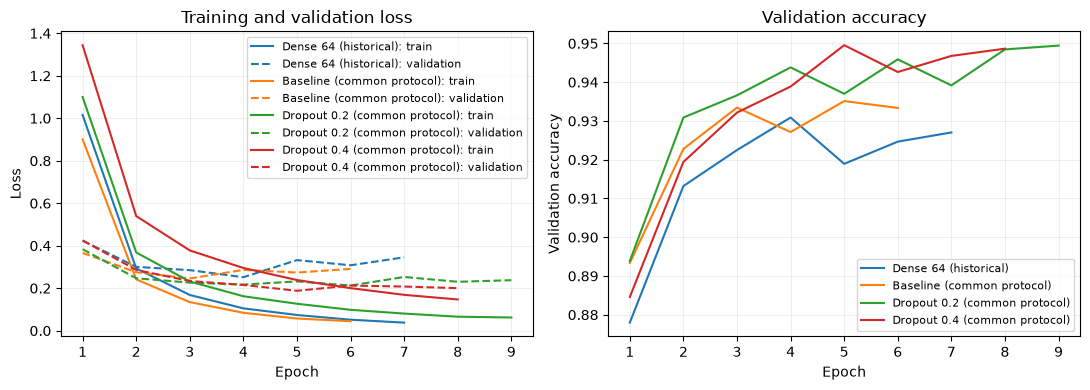

In [15]:
available_histories = {}
for name, path in available_artifacts.items():
    history_path = path.with_name(path.stem + "_history.json")
    if history_path.exists():
        available_histories[name] = json.loads(history_path.read_text())
    else:
        print(f"No saved history for {name}.")

if available_histories:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, values in available_histories.items():
        epochs = range(1, len(values["loss"]) + 1)
        line, = axes[0].plot(epochs, values["loss"], label=f"{name}: train")
        axes[0].plot(epochs, values["val_loss"], linestyle="--",
                     color=line.get_color(), label=f"{name}: validation")
        axes[1].plot(epochs, values["val_accuracy"], label=name)
    axes[0].set(xlabel="Epoch", ylabel="Loss", title="Training and validation loss")
    axes[1].set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

## 6. Analysis and next steps

All three common-protocol runs are complete. Their saved restored models give:

| Dropout | Validation accuracy | Validation loss | Errors | Selected epoch |
|---|---:|---:|---:|---:|
| 0 | 93.35% | 0.2458 | 674 | 3 |
| 0.2 | 94.59% | 0.2126 | 548 | 6 |
| 0.4 | 94.95% | 0.1878 | 511 | 5 |

Dropout 0.4 is the current candidate: +1.61 percentage points of accuracy and 163 fewer errors (24.2% fewer) than the common-protocol baseline. Both dropout rates improve accuracy and loss, with unchanged parameter counts. These conclusions concern this single-seed study, not a universally optimal rate.

Validation loss eventually rises for all three models, so EarlyStopping remains useful. Training runs with active dropout are harder than validation with dropout disabled; the train/validation accuracy gap alone is not evidence of better generalization. Compare saved restored models, not last-epoch scores. Historical models remain contextual because their preliminary dataset iteration differed.



The detailed analysis is in `reports/dropout_study.md`. Multi-seed confirmation and further interventions have not yet been run. Future training is run by the user; this analysis update launches none.